# The Sugar Trap: Healthy Snacking Market Gap Analysis

**Amalitech Data Engineering Project Assessment**  
**Client:** Helix CPG Partners  
**Data source:** [Open Food Facts](https://world.openfoodfacts.org/data)

## Project objective

Assess the nutritional positioning of six snack categories and identify products and categories where a **high-protein, low-sugar** profile is relatively uncommon. The analysis also examines ingredient mentions among products that meet the selected nutritional profile.

## Questions addressed

1. What does sugar and protein content look like across the six categories?
2. How many sampled products meet the exploratory high-protein, low-sugar profile?
3. Which categories have the lowest share of products meeting that profile?
4. Which protein-related ingredients are most frequently mentioned in the qualifying products?

> **Interpretation:** Open Food Facts describes products and their recorded attributes. It does not provide direct measures of consumer demand, sales or market share. Findings therefore indicate *potential nutritional-positioning whitespace*, not proven consumer demand.

## 1. Environment and imports

The notebook uses Pandas for data processing, Requests for retrieving the export, and Matplotlib/Seaborn for visual analysis. The source export is large, so the ingestion step reads it in chunks and retains a bounded sample.

In [1]:
%pip install -q pandas requests matplotlib seaborn numpy

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

## 2. Data acquisition

The Open Food Facts product export is tab-separated even though the downloaded file has a `.csv` extension. Only the fields needed for this assessment are selected.

### Sampling approach and limitation

This notebook reads the **first 500,000 records** encountered in the export, in chunks of 25,000 rows. This is a bounded **convenience sample**, not a random or statistically representative sample of the global food market. Product and category counts in this notebook describe this sample only.

In [3]:
DATA_URL = (
    "https://static.openfoodfacts.org/data/"
    "en.openfoodfacts.org.products.csv"
)

REQUIRED_COLUMNS = [
    "code",
    "product_name",
    "categories_tags",
    "sugars_100g",
    "proteins_100g",
    "fat_100g",
    "fiber_100g",
    "ingredients_text",
]

SAMPLE_SIZE = 500_000
CHUNK_SIZE = 25_000

### Stream and read the sample

`requests.get(..., stream=True)` avoids loading the entire remote export into memory at once. Pandas' `chunksize` reads the response in manageable portions. The selected chunks are then combined into the 500,000-row analysis sample.

In [4]:
response = requests.get(
    DATA_URL,
    stream=True,
    headers={"User-Agent": "SugarTrapAnalysis/1.0"},
    timeout=(30, 300),
)
response.raise_for_status()
response.raw.decode_content = True

chunks = []
rows_collected = 0

try:
    reader = pd.read_csv(
        response.raw,
        sep="\t",
        usecols=REQUIRED_COLUMNS,
        chunksize=CHUNK_SIZE,
        low_memory=False,
    )

    for chunk in reader:
        remaining = SAMPLE_SIZE - rows_collected
        if len(chunk) > remaining:
            chunk = chunk.iloc[:remaining]

        chunks.append(chunk)
        rows_collected += len(chunk)

        if rows_collected % 100_000 == 0 or rows_collected == SAMPLE_SIZE:
            print(f"Collected: {rows_collected:,} rows")

        if rows_collected >= SAMPLE_SIZE:
            break
finally:
    response.close()

if not chunks:
    raise RuntimeError("No rows were retrieved from the Open Food Facts export.")

raw_df = pd.concat(chunks, ignore_index=True)
del chunks

print("Sample shape:", raw_df.shape)
display(raw_df.head())

Collected: 100,000 rows
Collected: 200,000 rows
Collected: 300,000 rows
Collected: 400,000 rows
Collected: 500,000 rows
Sample shape: (500000, 8)


,code,product_name,categories_tags,ingredients_text,fat_100g,sugars_100g,fiber_100g,proteins_100g
0,NaN,NaN,NaN,"en:to-be-completed,en:nutrition-facts-complete...",NaN,NaN,NaN,NaN
1,NaN,"en:palm-oil-free,en:vegan-status-unknown,en:ve...","en:e322,en:e322i","en:fat-in-high-quantity,en:saturated-fat-in-hi...",NaN,NaN,NaN,NaN
2,NaN,"en:palm-oil-free,en:non-vegan,en:vegetarian","en:e322,en:e322i,en:e330,en:e407,en:e412,en:e4...","en:fat-in-moderate-quantity,en:saturated-fat-i...",0.378651,NaN,NaN,NaN
3,NaN,"en:palm-oil-free,en:non-vegan,en:vegetarian-st...","en:e270,en:e322,en:e322i,en:e407,en:e412,en:e4...","en:fat-in-moderate-quantity,en:saturated-fat-i...",2.278935,NaN,NaN,NaN
4,NaN,"en:palm-oil-free,en:non-vegan,en:vegetarian","en:e322,en:e322i,en:e330,en:e407,en:e412,en:e4...","en:fat-in-moderate-quantity,en:saturated-fat-i...",NaN,NaN,NaN,NaN


## 3. Category engineering

The source `categories_tags` field contains comma-separated tags. The tags were first inspected in the sample, then a set of explicit English-language tags was selected for each business category. Broad or ambiguous tags (for example, `en:sweet-snacks`, `en:barbecue-sauces` and `en:chocolate-chip-cookies`) are not used as category rules because they can include unrelated products.

A product can match more than one target category. To assign one primary category consistently, the following priority is applied:

1. Snack Bars
2. Biscuits
3. Crackers
4. Chips
5. Confectionery
6. Nuts

This priority is an analytical classification choice, not an official Open Food Facts hierarchy. Original category tags are retained for traceability.

In [5]:
CATEGORY_TAGS = {
    "Snack Bars": {
        "en:cereal-bars",
        "en:protein-bars",
        "en:energy-bars",
        "en:fruits-cereal-bars",
        "en:nut-bars",
        "en:protein-energy-bars",
        "en:snack-bar",
        "en:cereal-bars-with-nuts",
        "en:chocolate-cereal-bars",
        "en:peanut-bars",
    },
    "Biscuits": {
        "en:biscuits",
    },
    "Crackers": {
        "en:crackers",
        "en:crackers-appetizers",
        "en:wheat-crackers",
        "en:small-crackers",
        "en:rice-crackers",
        "en:crackers-breakfast",
        "en:graham-crackers",
        "en:sandwich-crackers",
        "en:baked-snack-crackers",
        "en:baked-crackers",
        "en:cheese-crackers",
        "en:cream-crackers",
        "en:bite-size-crackers",
    },
    "Chips": {
        "en:crisps",
        "en:potato-crisps",
        "en:corn-chips",
        "en:flavoured-potato-crisps",
        "en:stacked-extruded-potato-crisps",
        "en:plantain-chips",
        "en:pita-chips",
        "en:potato-crisps-in-sunflower-oil",
        "en:flavoured-corn-crisps",
        "en:chips",
        "en:ketchup-crisps",
        "en:salt-and-vinegar-crisps",
        "en:barbecue-crisps",
        "en:plantain-crisps",
        "en:wavy-potato-crisps",
        "en:crisps-made-from-reconstituted-potato",
    },
    "Confectionery": {
        "en:confectioneries",
        "en:candy-chocolate-bars",
        "en:chocolate-covered-nuts",
        "en:chocolate-covered-nuts-and-fruits",
        "en:nut-confectioneries",
        "en:fruit-confectioneries",
        "en:candy-canes",
        "en:chocolates-with-hazelnuts",
        "en:dark-chocolate-bar",
        "en:milk-chocolate-bar",
    },
    "Nuts": {
        "en:nuts",
        "en:peanuts",
        "en:roasted-nuts",
        "en:roasted-peanuts",
        "en:salted-nuts",
        "en:cashew-nuts",
        "en:shelled-nuts",
        "en:walnuts",
    },
}

CATEGORY_PRIORITY = list(CATEGORY_TAGS.keys())
print("Category priority:", CATEGORY_PRIORITY)

Category priority: ['Snack Bars', 'Biscuits', 'Crackers', 'Chips', 'Confectionery', 'Nuts']


In [6]:
def get_matching_categories(category_string):
    """Return target categories whose explicit tags occur in a product's tag string."""
    if not isinstance(category_string, str):
        return []

    product_tags = {
        tag.strip().lower()
        for tag in category_string.split(",")
        if tag.strip()
    }

    return [
        category
        for category in CATEGORY_PRIORITY
        if product_tags.intersection(CATEGORY_TAGS[category])
    ]


matched_categories = raw_df["categories_tags"].apply(get_matching_categories)
raw_df["primary_category"] = matched_categories.apply(
    lambda categories: categories[0] if categories else pd.NA
)

snack_df = raw_df.loc[raw_df["primary_category"].notna()].copy()

category_counts = (
    snack_df["primary_category"]
    .value_counts()
    .reindex(CATEGORY_PRIORITY, fill_value=0)
)

print("Source sample records:", len(raw_df))
print("Products matching target categories:", len(snack_df))
print(
    "Products matching multiple target categories:",
    matched_categories.loc[snack_df.index].map(len).gt(1).sum(),
)
display(category_counts.rename("Product Count").to_frame())

Source sample records: 500000
Products matching target categories: 29152
Products matching multiple target categories: 391


,Product Count
primary_category,
Snack Bars,897
Biscuits,6821
Crackers,1370
Chips,3296
Confectionery,15040
Nuts,1728


## 4. Data quality assessment and cleaning

The initial quality assessment is performed on the extracted snack records. Missing nutrient values are not replaced with zero: an unreported value is unknown, not evidence that the product contains none of that nutrient.

For nutrients measured per 100g, values below 0 or above 100 are treated as biologically implausible. Invalid measurements are changed to missing values rather than deleting an entire product, so valid measurements for other analyses can be retained. Records without a product name are excluded from the cleaned product export. The core nutrient dataset requires both sugar and protein measurements.

In [7]:
NUTRIENT_COLUMNS = [
    "sugars_100g",
    "proteins_100g",
    "fat_100g",
    "fiber_100g",
]

initial_quality_report = pd.DataFrame({
    "Missing Count": snack_df.isna().sum(),
    "Missing Percentage": (snack_df.isna().mean() * 100).round(2),
})

valid_codes = snack_df["code"].dropna()
initial_duplicate_rows = valid_codes.duplicated(keep=False).sum()

print("Initial snack records:", len(snack_df))
print("Rows with duplicate product codes:", initial_duplicate_rows)
display(initial_quality_report)

Initial snack records: 29152
Rows with duplicate product codes: 0


,Missing Count,Missing Percentage
code,0,0.00
product_name,301,1.03
categories_tags,0,0.00
ingredients_text,4929,16.91
fat_100g,20922,71.77
sugars_100g,20998,72.03
fiber_100g,22579,77.45
proteins_100g,20928,71.79
primary_category,0,0.00


In [8]:
# Convert nutrient columns to numeric values before validation.
cleaned_snack_df = snack_df.copy()
cleaned_snack_df[NUTRIENT_COLUMNS] = cleaned_snack_df[NUTRIENT_COLUMNS].apply(
    pd.to_numeric, errors="coerce"
)

invalid_mask = (
    (cleaned_snack_df[NUTRIENT_COLUMNS] < 0)
    | (cleaned_snack_df[NUTRIENT_COLUMNS] > 100)
)

invalid_report = pd.DataFrame({
    "Invalid Count": invalid_mask.sum(),
    "Invalid Percentage of Rows": (invalid_mask.mean() * 100).round(3),
})

print("Invalid nutrient measurements:", int(invalid_mask.sum().sum()))
print("Products affected:", int(invalid_mask.any(axis=1).sum()))
display(invalid_report)

# Replace only the invalid measurements; preserve other valid product data.
cleaned_snack_df[NUTRIENT_COLUMNS] = cleaned_snack_df[NUTRIENT_COLUMNS].mask(
    invalid_mask
)

Invalid nutrient measurements: 15
Products affected: 13


,Invalid Count,Invalid Percentage of Rows
sugars_100g,8,0.027
proteins_100g,0,0.000
fat_100g,6,0.021
fiber_100g,1,0.003


In [9]:
# Normalize product names and exclude missing/blank names.
cleaned_snack_df["product_name"] = (
    cleaned_snack_df["product_name"].astype("string").str.strip()
)
cleaned_snack_df["product_name"] = cleaned_snack_df["product_name"].replace(
    "", pd.NA
)

before_name_filter = len(cleaned_snack_df)
cleaned_snack_df = cleaned_snack_df.dropna(subset=["product_name"]).copy()
removed_missing_names = before_name_filter - len(cleaned_snack_df)

# No duplicate or missing product codes were found in this sample, but this
# safeguard makes the product-level export deterministic if the source changes.
cleaned_snack_df = cleaned_snack_df.dropna(subset=["code"])
cleaned_snack_df = cleaned_snack_df.drop_duplicates(subset=["code"], keep="first")

# Sugar/protein analysis requires both measurements to be present and valid.
core_analysis_df = cleaned_snack_df.dropna(
    subset=["sugars_100g", "proteins_100g"]
).copy()

print("Removed products with missing/blank names:", removed_missing_names)
print("Cleaned snack dataset:", cleaned_snack_df.shape)
print("Core nutrient dataset:", core_analysis_df.shape)

Removed products with missing/blank names: 301
Cleaned snack dataset: (28851, 9)
Core nutrient dataset: (8042, 9)


In [10]:
# Recalculate category-level data completeness after all cleaning steps.
cleaned_category_counts = cleaned_snack_df.groupby("primary_category").size()
core_category_counts = core_analysis_df.groupby("primary_category").size()

category_quality = pd.DataFrame({
    "Cleaned Products": cleaned_category_counts,
    "Products with Sugar and Protein": core_category_counts,
}).fillna(0)

category_quality["Products with Sugar and Protein"] = (
    category_quality["Products with Sugar and Protein"].astype(int)
)
category_quality["Core Data Completeness (%)"] = (
    category_quality["Products with Sugar and Protein"]
    / category_quality["Cleaned Products"] * 100
).round(2)

category_quality = category_quality.reindex(CATEGORY_PRIORITY)
display(category_quality)

,Cleaned Products,Products with Sugar and Protein,Core Data Completeness (%)
primary_category,,,
Snack Bars,882,485,54.99
Biscuits,6751,1917,28.40
Crackers,1349,498,36.92
Chips,3242,1618,49.91
Confectionery,14951,2649,17.72
Nuts,1676,875,52.21


### Export cleaned datasets

Two CSV outputs are created:

- `cleaned_snack_products.csv`: classified snack products with identifiable names; incomplete nutrient fields are retained where possible.
- `core_nutrient_analysis.csv`: products with valid sugar and protein measurements, used for the nutrient matrix and category comparisons.

The source export itself is not written into the repository.

In [11]:
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

cleaned_snack_df.to_csv(
    output_dir / "cleaned_snack_products.csv",
    index=False,
)
core_analysis_df.to_csv(
    output_dir / "core_nutrient_analysis.csv",
    index=False,
)

print("Exported:")
print(output_dir / "cleaned_snack_products.csv")
print(output_dir / "core_nutrient_analysis.csv")

Exported:
outputs/cleaned_snack_products.csv
outputs/core_nutrient_analysis.csv


## 5. Exploratory data analysis

The core dataset contains products with recorded, valid sugar and protein measurements. All nutrient values are expressed per 100g to support comparisons across products with different serving sizes.

In [12]:
nutrient_summary = core_analysis_df[
    ["sugars_100g", "proteins_100g"]
].describe(percentiles=[0.25, 0.50, 0.75])

display(nutrient_summary.round(2))

,sugars_100g,proteins_100g
count,8042.00,8042.00
mean,26.31,7.42
std,24.10,6.78
min,0.00,0.00
25%,3.57,3.57
50%,22.58,6.00
75%,45.00,8.33
max,100.00,89.29


In [13]:
category_summary = (
    core_analysis_df
    .groupby("primary_category")
    .agg(
        product_count=("code", "nunique"),
        average_sugar=("sugars_100g", "mean"),
        median_sugar=("sugars_100g", "median"),
        average_protein=("proteins_100g", "mean"),
        median_protein=("proteins_100g", "median"),
    )
    .round(2)
    .sort_values("average_sugar", ascending=False)
)

display(category_summary)

,product_count,average_sugar,median_sugar,average_protein,median_protein
primary_category,,,,,
Confectionery,2649,50.50,52.50,3.96,3.33
Biscuits,1917,27.19,29.60,5.99,5.70
Snack Bars,485,23.88,25.00,12.26,8.33
Nuts,875,7.59,4.58,19.44,20.00
Crackers,498,5.01,3.33,9.14,8.85
Chips,1618,3.06,2.50,6.28,6.00


### Sugar distribution by category

The boxplot compares the median, interquartile range and potential outliers in sugar content across the six categories. Unusually high but physically possible values are retained; they are not automatically treated as data errors.

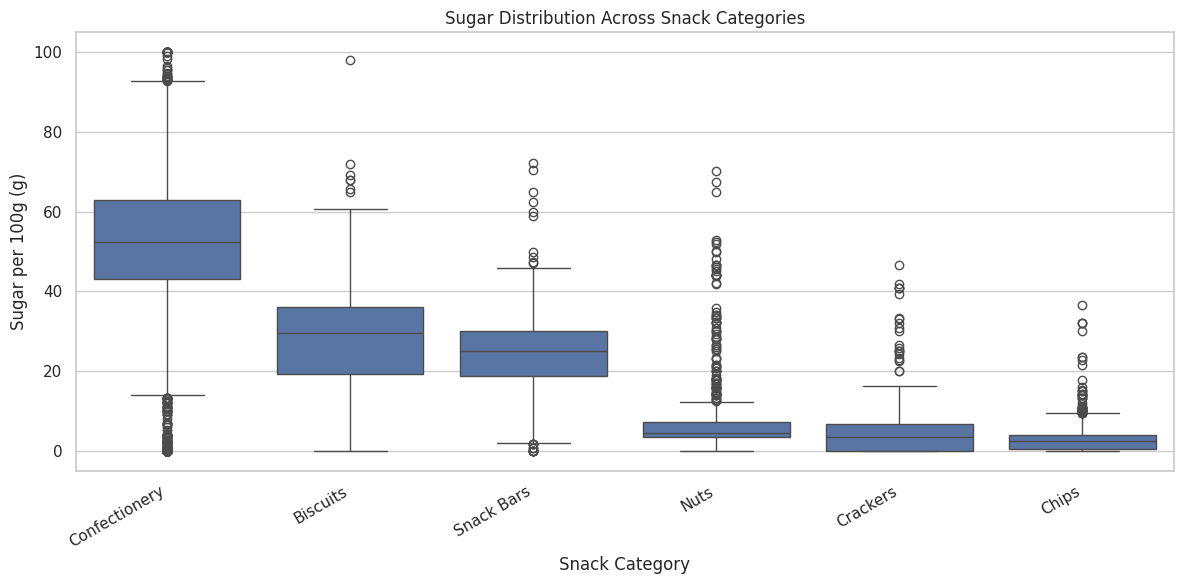

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=core_analysis_df,
    x="primary_category",
    y="sugars_100g",
    order=category_summary.index.tolist(),
)
plt.title("Sugar Distribution Across Snack Categories")
plt.xlabel("Snack Category")
plt.ylabel("Sugar per 100g (g)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Protein distribution by category

This boxplot compares protein content and helps distinguish categories with consistently higher protein levels from categories where only a small number of products have unusually high protein values.

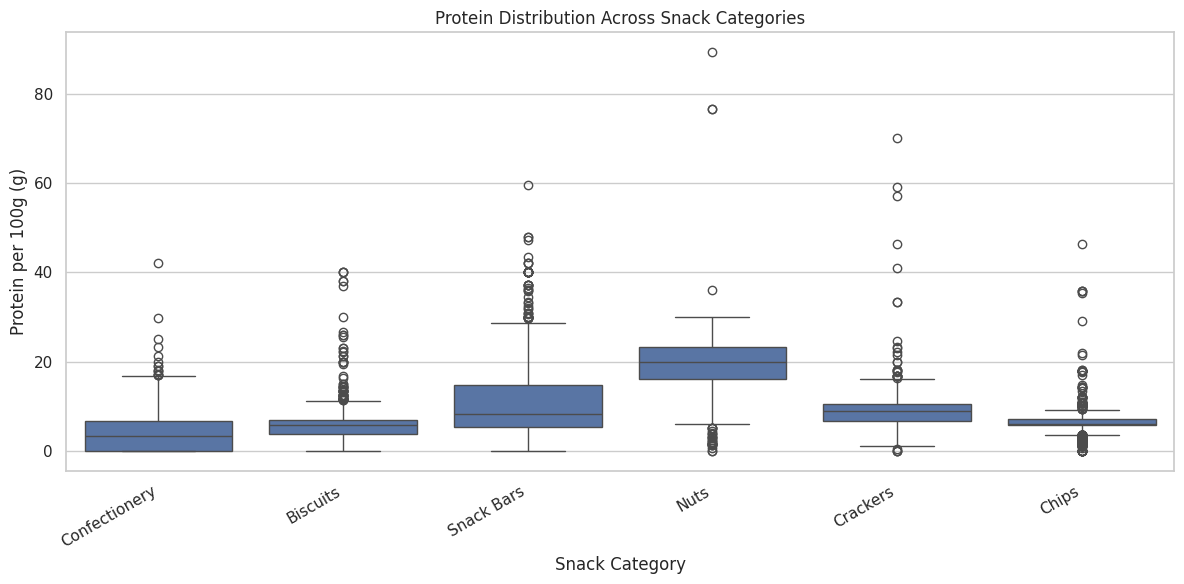

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=core_analysis_df,
    x="primary_category",
    y="proteins_100g",
    order=category_summary.index.tolist(),
)
plt.title("Protein Distribution Across Snack Categories")
plt.xlabel("Snack Category")
plt.ylabel("Protein per 100g (g)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Sugar versus protein: Nutrient Matrix

The scatter plot shows the relationship between sugar and protein. The dashed reference lines mark the sample's 25th percentile for sugar and 75th percentile for protein. These are exploratory, sample-relative cutoffs—not regulatory or universal nutrition claims.

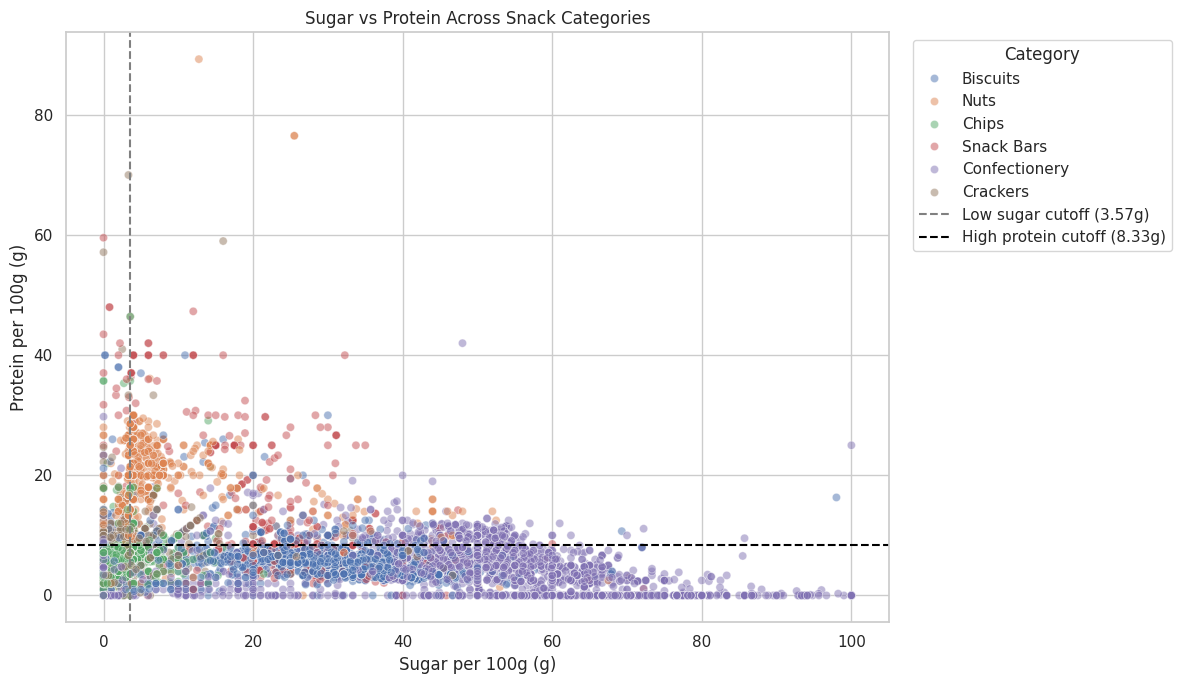

Low-sugar threshold (25th percentile): 3.57g/100g
High-protein threshold (75th percentile): 8.33g/100g


In [16]:
LOW_SUGAR_THRESHOLD = core_analysis_df["sugars_100g"].quantile(0.25)
HIGH_PROTEIN_THRESHOLD = core_analysis_df["proteins_100g"].quantile(0.75)

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=core_analysis_df,
    x="sugars_100g",
    y="proteins_100g",
    hue="primary_category",
    alpha=0.5,
    s=35,
)
plt.axvline(
    LOW_SUGAR_THRESHOLD,
    linestyle="--",
    color="gray",
    label=f"Low sugar cutoff ({LOW_SUGAR_THRESHOLD:.2f}g)",
)
plt.axhline(
    HIGH_PROTEIN_THRESHOLD,
    linestyle="--",
    color="black",
    label=f"High protein cutoff ({HIGH_PROTEIN_THRESHOLD:.2f}g)",
)
plt.title("Sugar vs Protein Across Snack Categories")
plt.xlabel("Sugar per 100g (g)")
plt.ylabel("Protein per 100g (g)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Low-sugar threshold (25th percentile): {LOW_SUGAR_THRESHOLD:.2f}g/100g")
print(f"High-protein threshold (75th percentile): {HIGH_PROTEIN_THRESHOLD:.2f}g/100g")

## 6. Nutritional profile and category comparison

A product is assigned to the exploratory **high-protein, low-sugar** profile when it has sugar at or below the sample's 25th percentile and protein at or above the sample's 75th percentile.

In [17]:
core_analysis_df["target_profile"] = (
    (core_analysis_df["sugars_100g"] <= LOW_SUGAR_THRESHOLD)
    & (core_analysis_df["proteins_100g"] >= HIGH_PROTEIN_THRESHOLD)
)

opportunity_df = core_analysis_df.loc[
    core_analysis_df["target_profile"]
].copy()

print("Products in core analysis:", len(core_analysis_df))
print("Products meeting the target profile:", len(opportunity_df))
print(
    "Target profile share:",
    f"{len(opportunity_df) / len(core_analysis_df) * 100:.2f}%",
)

Products in core analysis: 8042
Products meeting the target profile: 580
Target profile share: 7.21%


In [18]:
category_totals = core_analysis_df.groupby("primary_category").size()
category_qualifying = opportunity_df.groupby("primary_category").size()

category_gap_summary = pd.DataFrame({
    "Core Products Analyzed": category_totals,
    "Qualifying Products": category_qualifying,
}).fillna(0)

category_gap_summary["Qualifying Products"] = (
    category_gap_summary["Qualifying Products"].astype(int)
)
category_gap_summary["Target Profile Share (%)"] = (
    category_gap_summary["Qualifying Products"]
    / category_gap_summary["Core Products Analyzed"] * 100
).round(2)
category_gap_summary["Outside Target Profile (%)"] = (
    100 - category_gap_summary["Target Profile Share (%)"]
).round(2)

category_gap_summary = category_gap_summary.reindex(CATEGORY_PRIORITY)
display(category_gap_summary.sort_values("Outside Target Profile (%)", ascending=False))

,Core Products Analyzed,Qualifying Products,Target Profile Share (%),Outside Target Profile (%)
primary_category,,,,
Confectionery,2649,13,0.49,99.51
Chips,1618,48,2.97,97.03
Snack Bars,485,19,3.92,96.08
Biscuits,1917,106,5.53,94.47
Nuts,875,221,25.26,74.74
Crackers,498,173,34.74,65.26


### Candidate's Choice: Category-level outside-target share

As an additional metric, the analysis compares the share of products in each category that fall **outside** the selected high-protein, low-sugar profile:

**Outside-target share = 100% − target-profile share**

This offers a simple comparison of current nutritional positioning across categories. It should not be interpreted as a proven commercial market gap: products outside the target profile may have other desirable attributes, and this dataset does not measure demand or sales.

In [19]:
quadrant_conditions = [
    (core_analysis_df["sugars_100g"] <= LOW_SUGAR_THRESHOLD)
    & (core_analysis_df["proteins_100g"] >= HIGH_PROTEIN_THRESHOLD),
    (core_analysis_df["sugars_100g"] <= LOW_SUGAR_THRESHOLD)
    & (core_analysis_df["proteins_100g"] < HIGH_PROTEIN_THRESHOLD),
    (core_analysis_df["sugars_100g"] > LOW_SUGAR_THRESHOLD)
    & (core_analysis_df["proteins_100g"] >= HIGH_PROTEIN_THRESHOLD),
]

quadrant_labels = [
    "High Protein / Low Sugar",
    "Low Protein / Low Sugar",
    "High Protein / High Sugar",
]

core_analysis_df["nutrient_quadrant"] = np.select(
    quadrant_conditions,
    quadrant_labels,
    default="Low Protein / High Sugar",
)

quadrant_summary = (
    core_analysis_df["nutrient_quadrant"]
    .value_counts()
    .rename("Product Count")
    .to_frame()
)
quadrant_summary["Percentage"] = (
    quadrant_summary["Product Count"] / len(core_analysis_df) * 100
).round(2)

display(quadrant_summary)

,Product Count,Percentage
nutrient_quadrant,,
Low Protein / High Sugar,4538,56.43
Low Protein / Low Sugar,1483,18.44
High Protein / High Sugar,1441,17.92
High Protein / Low Sugar,580,7.21


### Examples of products meeting the target profile

The following products are examples found in the Open Food Facts sample. They are not independently tested or endorsed product recommendations. High recorded nutrient values should be interpreted in the context of data quality and ingredient information.

In [20]:
display(
    opportunity_df[
        ["product_name", "primary_category", "sugars_100g", "proteins_100g"]
    ]
    .sort_values("proteins_100g", ascending=False)
    .head(20)
)

,product_name,primary_category,sugars_100g,proteins_100g
53832,protein PUFFS Garlic Parmesan,Crackers,3.333333,70.000000
230335,Opti-Meal Protein Bars strawberry,Snack Bars,0.000000,59.555556
148259,Pork crackling dippers,Crackers,0.000000,57.142857
12781,Perfectbar,Snack Bars,0.800000,48.000000
12780,Barretta perfectbar,Snack Bars,0.800000,48.000000
129597,TOMATO BASIL PIZZA CRISPS,Chips,3.571429,46.428571
129596,PEPPERONI PIZZA CRISPS,Crackers,3.571429,46.428571
92944,Crispy bars marshmallow,Snack Bars,0.000000,43.478261
12959,K Crisp,Snack Bars,2.200000,42.000000
12437,Crackers al rosmarino,Crackers,2.500000,41.000000


## 7. Hidden Gem: Ingredient mentions in qualifying products

The ingredient analysis is restricted to products in the high-protein, low-sugar target profile. Simple English-language keyword patterns are used to count products mentioning selected protein-related ingredients. A product is counted once per source, even if the term appears more than once.

This is a **mention-frequency analysis**, not an estimate of ingredient quantity or protein contribution. Multilingual ingredient descriptions, synonyms and incomplete ingredient lists may cause undercounting.

In [21]:
gem_df = opportunity_df.copy()

available_ingredients = (
    gem_df["ingredients_text"].fillna("").str.strip().ne("")
)

print("Qualifying products:", len(gem_df))
print("Products with ingredient information:", int(available_ingredients.sum()))
print("Products without ingredient information:", int((~available_ingredients).sum()))

Qualifying products: 580
Products with ingredient information: 459
Products without ingredient information: 121


In [22]:
PROTEIN_SOURCE_PATTERNS = {
    "Whey": r"\bwhey\b",
    "Peanuts": r"\bpeanuts?\b",
    "Soy-derived ingredients": (
        r"\bsoy protein\b|\bsoya protein\b|"
        r"\bsoybeans?\b|\bsoya beans?\b|"
        r"\bsoy flour\b|\bsoya flour\b"
    ),
    "Almonds": r"\balmonds?\b",
    "Pea protein": r"\bpea protein\b|\bpea protein isolate\b",
    "Milk protein-related terms": (
        r"\bmilk protein\b|\bmilk powder\b|"
        r"\bmilk solids\b|\bcasein\b"
    ),
    "Egg protein-related terms": r"\begg whites?\b|\begg powder\b",
    "Lentils": r"\blentils?\b",
}

ingredient_text = gem_df["ingredients_text"].fillna("").str.lower()
source_counts = {
    source: int(ingredient_text.str.contains(pattern, regex=True, na=False).sum())
    for source, pattern in PROTEIN_SOURCE_PATTERNS.items()
}

protein_sources = pd.Series(source_counts, name="Products Mentioning Source")
protein_sources = protein_sources.sort_values(ascending=False)
display(protein_sources.to_frame())

print("Top three ingredient-source mentions:")
display(protein_sources.head(3).to_frame())

,Products Mentioning Source
Soy-derived ingredients,120
Peanuts,78
Whey,69
Almonds,60
Milk protein-related terms,14
Lentils,9
Pea protein,5
Egg protein-related terms,2


Top three ingredient-source mentions:


,Products Mentioning Source
Soy-derived ingredients,120
Peanuts,78
Whey,69


## 8. Executive interpretation and limitations

### Preliminary findings from this sample

- **Confectionery** has the highest average sugar (50.50g/100g) and lowest average protein (3.96g/100g) among the six categories in the core analytical sample.
- **Nuts** have the highest median protein (20.00g/100g) and average protein (19.44g/100g).
- **Snack Bars** show a wider range of protein positioning, including some products with substantially higher recorded protein.
- **580 of 8,042 products (7.21%)** meet the exploratory target profile based on the sample's 25th-percentile sugar and 75th-percentile protein thresholds.
- Of the 459 qualifying products with ingredient information, the most frequently detected keyword groups were soy-derived ingredients (120 products), peanuts (78), and whey (69).

### Preliminary recommendation

Confectionery is a **candidate category for further investigation** because only 0.49% of its products in the core analytical sample meet the exploratory high-protein, low-sugar profile. A possible R&D direction is to explore a confectionery product that approaches or exceeds **8.33g protein per 100g** while keeping sugar at or below **3.57g per 100g**. Soy-derived ingredients, peanuts and whey are potential formulation directions to investigate, subject to recipe, allergen, taste, cost and regulatory testing.

### Limitations

1. The analysis uses the first 500,000 rows of the export, a convenience sample that may be affected by source ordering and is not a representative global market sample.
2. Open Food Facts is a collaborative database. Nutritional and ingredient information is incomplete and may contain errors. Core nutrient completeness varies by category.
3. Category assignment uses selected explicit tags and a priority order. Multi-category products receive one primary category, so classification choices affect category counts.
4. The high-protein and low-sugar thresholds are sample quartiles, not regulatory or universal nutrition standards.
5. The outside-target share is a descriptive positioning metric, not evidence of unmet consumer demand, sales potential or market size.
6. Ingredient keyword matches indicate mentions, not ingredient quantities or their contribution to total protein. The patterns are primarily English-language and may miss translations and synonyms.

**Conclusion:** The results identify nutritional positioning patterns and candidate areas for product development research. Consumer research, a broader and more representative dataset, competitor validation and product testing would be needed before making a commercial launch decision.